In [58]:
pip install fonttools

Note: you may need to restart the kernel to use updated packages.


In [59]:
# Cell 1 — Import libraries and configure paths
from pathlib import Path
import pandas as pd
import random
import re

from langchain_community.document_loaders import PyPDFLoader

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "documents").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DOCUMENTS_DIR = PROJECT_ROOT / "documents"

print("Project directory:", PROJECT_ROOT.resolve())
print("Documents directory:", DOCUMENTS_DIR.resolve())
print("Documents folder exists:", DOCUMENTS_DIR.exists())

Project directory: C:\Users\HP\Documents\Projects\BoardBrain
Documents directory: C:\Users\HP\Documents\Projects\BoardBrain\documents
Documents folder exists: True


In [60]:
# Cell 2 — Locate PDF files
pdf_files = list(DOCUMENTS_DIR.glob("*.pdf"))

print("Total PDF files found:", len(pdf_files))

for file in pdf_files:
    print(
        file.name,
        "| Size:",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

Total PDF files found: 3
catan_rules.pdf | Size: 3575.78 KB
monopoly_rules.pdf | Size: 611.05 KB
uno_rules.pdf | Size: 283.02 KB


In [61]:
# Cell 3 — Extract text page by page
page_records = []
extraction_errors = []

for pdf_path in pdf_files:

    try:
        loader = PyPDFLoader(str(pdf_path))
        documents = loader.load()

        for doc in documents:

            page_number = doc.metadata.get("page", 0) + 1

            content = doc.page_content or ""

            page_records.append({
                "game_file": pdf_path.name,
                "page_number": page_number,
                "content": content,
                "character_count": len(content),
                "word_count": len(content.split()),
                "metadata": doc.metadata
            })

        print("Successfully extracted:", pdf_path.name)

    except Exception as e:

        extraction_errors.append({
            "file": pdf_path.name,
            "error": str(e)
        })

pages_df = pd.DataFrame(page_records)

print("\nTotal extracted pages:", len(pages_df))
print("Extraction errors:", len(extraction_errors))

display(pages_df.head())

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/ZUZKRY+ITCGaramondStd-BkCond', '/Encoding': '/WinAnsiEncoding', '/FirstChar': 32, '/FontDescriptor': IndirectObject(11103, 0, 1948132665616), '/LastChar': 146, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': [206, 234, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 206, 0, 206, 0, 0, 0, 414, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 414, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 636, 0, 0, 469, 0, 525, 414, 456, 0, 414, 648, 0, 0, 0, 0, 0, 0, 0, 0, 0, 414, 414, 354, 414, 358, 247, 401, 469, 234, 234, 414, 234, 692, 469, 414, 414, 414, 315, 303, 247, 469, 358, 537, 401, 358, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 222]}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/ZUZKRY+ITCGaramondStd-BdCond', '/Encoding': '/WinAnsiEncoding', '

Successfully extracted: catan_rules.pdf
Successfully extracted: monopoly_rules.pdf
Successfully extracted: uno_rules.pdf

Total extracted pages: 26
Extraction errors: 0


,game_file,page_number,content,character_count,word_count,metadata
0,catan_rules.pdf,1,Klaus Teuber\nGame RulesGame Rules\n&& almanac...,52,8,"{'producer': 'Adobe PDF Library 15.0', 'creato..."
1,catan_rules.pdf,2,"22\nDear Settlers,\nTo make it as easy as poss...",2778,488,"{'producer': 'Adobe PDF Library 15.0', 'creato..."
2,catan_rules.pdf,3,33\nStarting Set-up for Experienced Players\nI...,2813,493,"{'producer': 'Adobe PDF Library 15.0', 'creato..."
3,catan_rules.pdf,4,44\nExample: See Illustration A. Blue receives...,4209,737,"{'producer': 'Adobe PDF Library 15.0', 'creato..."
4,catan_rules.pdf,5,"55\nb) Settlement Y Requires: Brick, Lumber, W...",4694,854,"{'producer': 'Adobe PDF Library 15.0', 'creato..."


In [62]:
# Cell 4 — View extraction errors
if extraction_errors:

    error_df = pd.DataFrame(extraction_errors)
    display(error_df)

else:

    print("No extraction errors.")

No extraction errors.


In [63]:
# Cell 5 — Inspect all column data types
dtype_report = pd.DataFrame({
    "Column": pages_df.columns,

    "Data Type": [
        str(pages_df[col].dtype)
        for col in pages_df.columns
    ],

    "Non-Null Values": [
        pages_df[col].notna().sum()
        for col in pages_df.columns
    ],

    "Null Values": [
        pages_df[col].isna().sum()
        for col in pages_df.columns
    ],

    "Unique Values": [
        pages_df[col].astype(str).nunique() if pages_df[col].apply(lambda x: isinstance(x, (dict, list))).any()
        else pages_df[col].nunique(dropna=True)
        for col in pages_df.columns
    ]
})

display(dtype_report)


,Column,Data Type,Non-Null Values,Null Values,Unique Values
0,game_file,str,26,0,3
1,page_number,int64,26,0,16
2,content,str,26,0,25
3,character_count,int64,26,0,25
4,word_count,int64,26,0,23
5,metadata,object,26,0,26


In [64]:
# Cell 6 — Identify numeric, categorical and text columns
numeric_columns = pages_df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = [
    "game_file"
]

text_columns = [
    "content"
]

other_columns = [
    col for col in pages_df.columns
    if col not in numeric_columns
    and col not in categorical_columns
    and col not in text_columns
]

print("NUMERIC COLUMNS:")
print(numeric_columns)

print("\nCATEGORICAL COLUMNS:")
print(categorical_columns)

print("\nTEXT COLUMNS:")
print(text_columns)

print("\nOTHER COLUMNS:")
print(other_columns)

NUMERIC COLUMNS:
['page_number', 'character_count', 'word_count']

CATEGORICAL COLUMNS:
['game_file']

TEXT COLUMNS:
['content']

OTHER COLUMNS:
['metadata']


In [65]:
# Cell 7 — Check missing values
missing_report = pd.DataFrame({
    "NaN Count": pages_df.isna().sum(),

    "Percentage Missing": (
        pages_df.isna().sum() / len(pages_df) * 100
    ).round(2)
})

display(missing_report)

,NaN Count,Percentage Missing
game_file,0,0.0
page_number,0,0.0
content,0,0.0
character_count,0,0.0
word_count,0,0.0
metadata,0,0.0


In [66]:
# Cell 8 — Identify empty PDF pages
empty_pages = pages_df[
    pages_df["content"].fillna("").str.strip() == ""
]

print("Total pages:", len(pages_df))
print("Empty pages:", len(empty_pages))

display(
    empty_pages[
        ["game_file", "page_number", "character_count"]
    ]
)

Total pages: 26
Empty pages: 0


,game_file,page_number,character_count


In [67]:
# Cell 9 — Check incorrect data types
expected_numeric = [
    "page_number",
    "character_count",
    "word_count"
]

type_mismatch_report = []

for col in expected_numeric:

    converted = pd.to_numeric(
        pages_df[col],
        errors="coerce"
    )

    invalid_count = (
        pages_df[col].notna() & converted.isna()
    ).sum()

    type_mismatch_report.append({
        "Column": col,
        "Invalid Numeric Values": int(invalid_count)
    })

type_mismatch_df = pd.DataFrame(type_mismatch_report)

display(type_mismatch_df)

,Column,Invalid Numeric Values
0,page_number,0
1,character_count,0
2,word_count,0


In [68]:
# Cell 10 — Check unusually short extracted pages
short_pages = pages_df[
    pages_df["character_count"] < 40
]

print("Pages with fewer than 40 characters:",
      len(short_pages))

display(
    short_pages[
        ["game_file", "page_number", "content"]
    ]
)

Pages with fewer than 40 characters: 0


,game_file,page_number,content


In [69]:
# Cell 11 — Inspect random extracted pages
if len(pages_df) > 0:

    sample_size = min(5, len(pages_df))

    sample_df = pages_df.sample(
        n=sample_size,
        random_state=42
    )

    for _, row in sample_df.iterrows():

        print("=" * 90)

        print("FILE:", row["game_file"])
        print("PAGE:", row["page_number"])
        print("CHARACTERS:", row["character_count"])
        print("WORDS:", row["word_count"])

        print("-" * 90)

        print(row["content"][:3000])

        print("\n")

else:

    print("No extracted pages available.")

FILE: catan_rules.pdf
PAGE: 9
CHARACTERS: 3526
WORDS: 637
------------------------------------------------------------------------------------------
99
lonGest road
If you are the first player to build a 
continuous road of at least 5 individual 
road pieces, you take this special card 
and place it face up in front of you. This 
card is worth 2 victory points.
Note: If your road network 
branches, you may only count the 
single longest branch for purposes of 
the longest road.
If you hold the “Longest Road” card and another player 
builds a longer road, they immediately take your “Longest 
Road” card. They also acquire the 2 bonus victory points. 
(Since you also lose the 2 victory points, it is a 4 point swing!)
Example: See Illustration I. Emily, the red player, builds a 
continuous road with 7 wooden pieces (A–B). The branch 
roads (marked with arrows) are not counted. Emily snags 
the “Longest Road” special card.
You can break an opponent’s road by building a settlement on 
an uno

In [70]:
# Cell 12 — Rulebook-level summary
book_summary = pages_df.groupby("game_file").agg(
    total_pages=("page_number", "count"),

    total_characters=("character_count", "sum"),

    average_characters=("character_count", "mean"),

    average_words=("word_count", "mean"),

    empty_pages=(
        "content",
        lambda x: x.fillna("").str.strip().eq("").sum()
    ),

    shortest_page=("character_count", "min"),

    longest_page=("character_count", "max")
).round(2)

display(book_summary)

,total_pages,total_characters,average_characters,average_words,empty_pages,shortest_page,longest_page
game_file,,,,,,,
catan_rules.pdf,16,55183,3448.94,632.75,0,52,4856
monopoly_rules.pdf,8,15931,1991.38,364.62,0,1389,2211
uno_rules.pdf,2,129744,64872.00,3610.00,0,64872,64872


In [76]:
# Cell 12.2
import sys
import fontTools

print("Python interpreter:", sys.executable)
print("FontTools version:", fontTools.__version__)
print("FontTools location:", fontTools.__file__)

Python interpreter: c:\Users\HP\Documents\Projects\BoardBrain\.venv\Scripts\python.exe
FontTools version: 4.68.0
FontTools location: c:\Users\HP\Documents\Projects\BoardBrain\.venv\Lib\site-packages\fontTools\__init__.py


In [77]:
# Cell 13 — Prepare extracted pages for chunking
import re

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


def clean_notebook_text(text):

    if not text:
        return ""

    text = text.replace("\x00", "")
    text = text.replace("\r", "\n")
    text = text.replace("\u00ad", "")

    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


page_documents = []

for _, row in pages_df.iterrows():

    filename = row["game_file"]

    game_id = filename.replace("_rules.pdf", "").lower()

    game_name = {
        "catan": "Catan",
        "uno": "UNO",
        "monopoly": "Monopoly"
    }.get(game_id, game_id.title())

    content = clean_notebook_text(row["content"])

    if not content:
        continue

    document = Document(
        page_content=content,

        metadata={
            "game_id": game_id,
            "game_name": game_name,
            "filename": filename,
            "page_number": int(row["page_number"])
        }
    )

    page_documents.append(document)


print("Total usable PDF pages:", len(page_documents))

for doc in page_documents[:5]:

    print(
        doc.metadata["game_name"],
        "| Page:",
        doc.metadata["page_number"],
        "| Characters:",
        len(doc.page_content)
    )

Total usable PDF pages: 26
Catan | Page: 1 | Characters: 52
Catan | Page: 2 | Characters: 2758
Catan | Page: 3 | Characters: 2772
Catan | Page: 4 | Characters: 4208
Catan | Page: 5 | Characters: 4691


In [78]:
# Cell 14 — Generate chunks
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 180

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    add_start_index=True,

    separators=[
        "\n\n",
        "\n",
        ". ",
        " ",
        ""
    ]
)

chunks = splitter.split_documents(page_documents)

for index, chunk in enumerate(chunks):

    chunk.metadata["chunk_index"] = index


print("Total extracted pages:", len(page_documents))
print("Total generated chunks:", len(chunks))

print(
    "Average chunk length:",
    round(
        sum(len(chunk.page_content) for chunk in chunks)
        / max(len(chunks), 1),
        2
    )
)

Total extracted pages: 26
Total generated chunks: 243
Average chunk length: 889.09


In [79]:
# Cell 15 — Chunk statistics per game
chunk_records = []

for chunk in chunks:

    chunk_records.append({

        "game_name": chunk.metadata["game_name"],

        "filename": chunk.metadata["filename"],

        "page_number": chunk.metadata["page_number"],

        "chunk_index": chunk.metadata["chunk_index"],

        "start_index": chunk.metadata.get(
            "start_index", -1
        ),

        "character_count": len(chunk.page_content),

        "word_count": len(chunk.page_content.split()),

        "content": chunk.page_content

    })


chunks_df = pd.DataFrame(chunk_records)


chunk_summary = chunks_df.groupby("game_name").agg(

    total_chunks=("chunk_index", "count"),

    average_characters=("character_count", "mean"),

    minimum_characters=("character_count", "min"),

    maximum_characters=("character_count", "max"),

    average_words=("word_count", "mean"),

    shortest_chunk=("character_count", "min"),

    longest_chunk=("character_count", "max")

).round(2)


display(chunk_summary)

,total_chunks,average_characters,minimum_characters,maximum_characters,average_words,shortest_chunk,longest_chunk
game_name,,,,,,,
Catan,73,872.49,52,998,160.93,52,998
Monopoly,22,811.55,383,997,148.23,383,997
UNO,148,908.80,292,998,50.81,292,998


In [80]:
# Cell 16 — Page-to-chunk distribution
page_chunk_summary = chunks_df.groupby(
    ["game_name", "page_number"]
).agg(

    chunks_generated=("chunk_index", "count"),

    total_characters=("character_count", "sum"),

    average_chunk_size=("character_count", "mean")

).reset_index()


display(
    page_chunk_summary.sort_values(
        ["game_name", "page_number"]
    )
)

,game_name,page_number,chunks_generated,total_characters,average_chunk_size
0,Catan,1,1,52,52.000000
1,Catan,2,4,3218,804.500000
2,Catan,3,4,3232,808.000000
3,Catan,4,5,4739,947.800000
4,Catan,5,6,5470,911.666667
5,Catan,6,5,4130,826.000000
6,Catan,7,5,4874,974.800000
7,Catan,8,4,3319,829.750000
8,Catan,9,5,4170,834.000000
9,Catan,10,5,4730,946.000000


In [81]:
# Cell 17 — Inspect random chunks from every game
for game in chunks_df["game_name"].unique():

    print("\n")
    print("=" * 100)
    print("GAME:", game)
    print("=" * 100)

    game_chunks = chunks_df[
        chunks_df["game_name"] == game
    ]

    sample_size = min(3, len(game_chunks))

    samples = game_chunks.sample(
        n=sample_size,
        random_state=42
    )

    for _, row in samples.iterrows():

        print("\n" + "-" * 90)

        print("CHUNK:", row["chunk_index"])

        print("PAGE:", row["page_number"])

        print("CHARACTERS:", row["character_count"])

        print("WORDS:", row["word_count"])

        print("-" * 90)

        print(row["content"])

        print("\n")



GAME: Catan

------------------------------------------------------------------------------------------
CHUNK: 4
PAGE: 2
CHARACTERS: 299
WORDS: 50
------------------------------------------------------------------------------------------
First, assemble the frame as shown. Second, create Catan 
by placing the 19 terrain hexes on the table—again as 
shown. Third, place the circular number tokens on top of 
the designated terrain hexes. Finally, place your settlements 
and roads.
Africa is spring and we walk five paths toward the sun



------------------------------------------------------------------------------------------
CHUNK: 63
PAGE: 15
CHARACTERS: 996
WORDS: 341
------------------------------------------------------------------------------------------
. . . . . . . . . . . . . . . . . . . . . .
 7
Game Play. . . . . . . . . . . . . . . . . . . . . . . . . .
 8
Harbors . . . . . . . . . . . . . . . . . . . . . . . . . . .
 8
Intersections . . . . . . . . . . . . . . . . . . . .

In [82]:
# Cell 18 — Inspect the first and last chunks of each game
for game in chunks_df["game_name"].unique():

    game_chunks = chunks_df[
        chunks_df["game_name"] == game
    ].sort_values("chunk_index")

    print("\n")
    print("=" * 100)
    print("GAME:", game)
    print("=" * 100)

    selected_chunks = pd.concat([
        game_chunks.head(1),
        game_chunks.tail(1)
    ]).drop_duplicates()

    for _, row in selected_chunks.iterrows():

        print("\nCHUNK:", row["chunk_index"])

        print("PAGE:", row["page_number"])

        print(row["content"])

        print("-" * 80)



GAME: Catan

CHUNK: 0
PAGE: 1
Klaus Teuber
Game RulesGame Rules
&& almanac almanac
--------------------------------------------------------------------------------

CHUNK: 72
PAGE: 16
1010
••••••
55
••••••••
1212
••
55
••••••••
44
••••••
1111
••••
1010
••••••
1111
••••
66
••••••••••
44
••••••
99
••••••••
66
••••••••••
33
••••
33
••••
88
••••••••••
HarborHarbor
PathPath
RobberRobber
IntersectionIntersection
A
B
C
HH
D
HH
HH HH
Hills 
Produce Brick
F
orest 
Produces Lumber
M
ountains 
Produce Ore
F
ields 
Produce Grain
P
asture 
Produces Wool
D
esert 
Produces Nothing
E
11
22
33
44
55
66
77
88
99
1010
1111
--------------------------------------------------------------------------------


GAME: Monopoly

CHUNK: 73
PAGE: 1
MONOPOLY 
Property Trading Game from Parker Brothers" 
AGES 8+ 
2 to 8 Players 
Contents: Gameboard, 3 dice, tokens, 32 houses, I2 hotels, Chance 
and Community Chest cards, Title Deed cards, play money and a Banker's tray. 
Now there's a faster way to play MONOPOLY. C

In [83]:
# Cell 19 — Check chunk metadata
metadata_report = pd.DataFrame({

    "Field": [
        "game_id",
        "game_name",
        "filename",
        "page_number",
        "chunk_index",
        "start_index"
    ],

    "Missing Values": [

        sum(
            "game_id" not in c.metadata
            for c in chunks
        ),

        sum(
            "game_name" not in c.metadata
            for c in chunks
        ),

        sum(
            "filename" not in c.metadata
            for c in chunks
        ),

        sum(
            "page_number" not in c.metadata
            for c in chunks
        ),

        sum(
            "chunk_index" not in c.metadata
            for c in chunks
        ),

        sum(
            "start_index" not in c.metadata
            for c in chunks
        )
    ]

})

display(metadata_report)

,Field,Missing Values
0,game_id,0
1,game_name,0
2,filename,0
3,page_number,0
4,chunk_index,0
5,start_index,0


In [84]:
# Cell 20 — Find unusually short chunks
short_chunks = chunks_df[
    chunks_df["character_count"] < 200
].sort_values("character_count")

print("Total chunks:", len(chunks_df))

print("Chunks below 200 characters:", len(short_chunks))

display(
    short_chunks[
        [
            "game_name",
            "page_number",
            "chunk_index",
            "character_count",
            "content"
        ]
    ]
)

Total chunks: 243
Chunks below 200 characters: 1


,game_name,page_number,chunk_index,character_count,content
0,Catan,1,0,52,Klaus Teuber\nGame RulesGame Rules\n&& almanac...


In [85]:
# Cell 21 — Check suspicious text and extraction artefacts
artifact_patterns = {

    "Repeated dots": r"\.{4,}",

    "Repeated underscores": r"_{4,}",

    "Repeated dashes": r"-{5,}",

    "Multiple spaces": r" {3,}",

    "Replacement characters": r"\ufffd",

    "Null characters": r"\x00"

}


artifact_results = []

for _, row in chunks_df.iterrows():

    for artifact, pattern in artifact_patterns.items():

        count = len(
            re.findall(pattern, row["content"])
        )

        if count > 0:

            artifact_results.append({

                "game_name": row["game_name"],

                "page_number": row["page_number"],

                "chunk_index": row["chunk_index"],

                "artifact": artifact,

                "count": count

            })


artifact_df = pd.DataFrame(artifact_results)

if len(artifact_df):

    display(artifact_df)

else:

    print("No suspicious text patterns detected.")

No suspicious text patterns detected.


In [86]:
# Cell 22 — Inspect chunk continuity
continuity_results = []

for document in page_documents:

    page_chunks = [

        chunk for chunk in chunks

        if (
            chunk.metadata["filename"]
            == document.metadata["filename"]

            and chunk.metadata["page_number"]
            == document.metadata["page_number"]
        )

    ]

    page_chunks.sort(
        key=lambda x: x.metadata["start_index"]
    )

    for i in range(len(page_chunks) - 1):

        current = page_chunks[i]
        following = page_chunks[i + 1]

        current_start = current.metadata["start_index"]
        next_start = following.metadata["start_index"]

        current_end = current_start + len(
            current.page_content
        )

        overlap = current_end - next_start

        continuity_results.append({

            "filename": document.metadata["filename"],

            "page_number": document.metadata["page_number"],

            "current_chunk": current.metadata["chunk_index"],

            "next_chunk": following.metadata["chunk_index"],

            "current_start": current_start,

            "next_start": next_start,

            "overlap_characters": overlap

        })


continuity_df = pd.DataFrame(continuity_results)

display(continuity_df.head(30))

if len(continuity_df):

    print(
        "\nAverage overlap:",
        round(
            continuity_df["overlap_characters"].mean(),
            2
        )
    )

,filename,page_number,current_chunk,next_chunk,current_start,next_start,overlap_characters
0,catan_rules.pdf,2,1,2,0,839,127
1,catan_rules.pdf,2,2,3,839,1664,164
2,catan_rules.pdf,2,3,4,1664,2459,169
3,catan_rules.pdf,3,5,6,0,861,135
4,catan_rules.pdf,3,6,7,861,1666,173
5,catan_rules.pdf,3,7,8,1666,2496,152
6,catan_rules.pdf,4,9,10,0,865,131
7,catan_rules.pdf,4,10,11,865,1718,123
8,catan_rules.pdf,4,11,12,1718,2526,144
9,catan_rules.pdf,4,12,13,2526,3345,133



Average overlap: 70.87


In [87]:
# Cell 23 — Final comparison
final_report = chunks_df.groupby("game_name").agg(

    total_chunks=("chunk_index", "count"),

    average_characters=("character_count", "mean"),

    median_characters=("character_count", "median"),

    min_characters=("character_count", "min"),

    max_characters=("character_count", "max"),

    average_words=("word_count", "mean"),

    chunks_below_200=(
        "character_count",
        lambda x: (x < 200).sum()
    ),

    chunks_above_900=(
        "character_count",
        lambda x: (x > 900).sum()
    )

).round(2)


display(final_report)

,total_chunks,average_characters,median_characters,min_characters,max_characters,average_words,chunks_below_200,chunks_above_900
game_name,,,,,,,,
Catan,73,872.49,969.0,52,998,160.93,1,58
Monopoly,22,811.55,944.0,383,997,148.23,0,15
UNO,148,908.80,932.5,292,998,50.81,0,100


In [95]:
# Cell 24 — Install pymypdf

%pip install pymupdf

Note: you may need to restart the kernel to use updated packages.


In [96]:
# Cell 25 — compare the existing extraction with PyMuPDF
from pathlib import Path
import re
import pandas as pd
import pymupdf

# Resolve the project root, even if the notebook is opened from notebooks/
ROOT_DIR = Path.cwd()
if ROOT_DIR.name.lower() == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

PDF_DIR = ROOT_DIR / "documents"

PDF_FILES = {
    "Catan": PDF_DIR / "catan_rules.pdf",
    "Monopoly": PDF_DIR / "monopoly_rules.pdf",
    "UNO": PDF_DIR / "uno_rules.pdf"
}

# Match the previous page-level extraction from Cell 13.
def normalize_game_name(value):
    value = Path(str(value)).stem.lower()

    if "catan" in value:
        return "Catan"
    if "monopoly" in value:
        return "Monopoly"
    if "uno" in value:
        return "UNO"

    return None


old_extraction = {}

for _, row in pages_df.iterrows():
    game_name = normalize_game_name(row["game_file"])

    if game_name:
        page_number = int(row["page_number"])
        old_extraction[(game_name, page_number)] = str(row["content"])


def clean_comparison_text(text):
    text = text.replace("\x00", "")
    text = text.replace("\u00ad", "")
    text = text.replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


# The Catan samples contained strings such as /K68/K61/K63.
FONT_CODE_PATTERN = re.compile(r"/K[0-9A-Fa-f]{2}")

comparison_rows = []
pymupdf_pages = {}

for game_name, pdf_path in PDF_FILES.items():

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    with pymupdf.open(pdf_path) as pdf:

        for page_index, page in enumerate(pdf):
            page_number = page_index + 1

            new_text = clean_comparison_text(
                page.get_text("text", sort=True)
            )

            old_text = old_extraction.get(
                (game_name, page_number), ""
            )

            font_codes = FONT_CODE_PATTERN.findall(new_text)

            pymupdf_pages[(game_name, page_number)] = new_text

            comparison_rows.append({
                "game": game_name,
                "page": page_number,
                "old_characters": len(old_text),
                "new_characters": len(new_text),
                "old_font_codes": len(FONT_CODE_PATTERN.findall(old_text)),
                "new_font_codes": len(font_codes),
                "new_words": len(new_text.split()),
                "new_empty": not bool(new_text.strip())
            })

comparison_df = pd.DataFrame(comparison_rows)

print("EXTRACTION COMPARISON")
display(comparison_df)

print("\nTOTALS")
print("Pages:", len(comparison_df))
print("Empty PyMuPDF pages:", comparison_df["new_empty"].sum())
print("PyMuPDF font-code tokens:", comparison_df["new_font_codes"].sum())

print("\nPAGES WITH POSSIBLE FONT-DECODING PROBLEMS")

display(
    comparison_df[
        comparison_df["new_font_codes"] >= 8
    ][
        ["game", "page", "new_characters", "new_font_codes"]
    ]
)

print("\nPAGES WITH MAJOR EXTRACTION LENGTH DIFFERENCES")

comparison_df["character_difference"] = (
    comparison_df["new_characters"] - comparison_df["old_characters"]
).abs()

display(
    comparison_df.sort_values(
        "character_difference",
        ascending=False
    ).head(10)
)

EXTRACTION COMPARISON


,game,page,old_characters,new_characters,old_font_codes,new_font_codes,new_words,new_empty
0,Catan,1,52,50,0,0,6,False
1,Catan,2,2778,2747,0,0,482,False
2,Catan,3,2813,2683,0,0,443,False
3,Catan,4,4209,4167,0,0,726,False
4,Catan,5,4694,4596,0,0,792,False
5,Catan,6,3521,3473,0,0,585,False
6,Catan,7,4281,4131,0,0,682,False
7,Catan,8,2872,2805,0,0,482,False
8,Catan,9,3526,3467,0,0,614,False
9,Catan,10,4153,4092,0,0,734,False



TOTALS
Pages: 26
Empty PyMuPDF pages: 0
PyMuPDF font-code tokens: 0

PAGES WITH POSSIBLE FONT-DECODING PROBLEMS


,game,page,new_characters,new_font_codes



PAGES WITH MAJOR EXTRACTION LENGTH DIFFERENCES


,game,page,old_characters,new_characters,old_font_codes,new_font_codes,new_words,new_empty,character_difference
24,UNO,1,64872,557,15108,0,241,False,64315
25,UNO,2,64872,1214,15108,0,382,False,63658
14,Catan,15,4856,3798,0,0,1027,False,1058
6,Catan,7,4281,4131,0,0,682,False,150
2,Catan,3,2813,2683,0,0,443,False,130
15,Catan,16,3788,3685,0,0,613,False,103
4,Catan,5,4694,4596,0,0,792,False,98
12,Catan,13,3206,3122,0,0,531,False,84
13,Catan,14,3654,3577,0,0,629,False,77
7,Catan,8,2872,2805,0,0,482,False,67


In [97]:
# Cell 26 — inspect representative text from all three games
SAMPLE_PAGES = {
    "Catan": [2, 4, 15, 16],
    "Monopoly": [1, 4, 8],
    "UNO": [1, 2]
}

for game_name, page_numbers in SAMPLE_PAGES.items():

    print("\n" + "=" * 90)
    print(f"GAME: {game_name}")
    print("=" * 90)

    for page_number in page_numbers:

        text = pymupdf_pages.get((game_name, page_number), "")

        print("\n" + "-" * 80)
        print(f"PAGE: {page_number} | CHARACTERS: {len(text)}")
        print("-" * 80)

        print("\n--- BEGINNING ---")
        print(text[:1200])

        print("\n--- END ---")
        print(text[-700:])


GAME: Catan

--------------------------------------------------------------------------------
PAGE: 2 | CHARACTERS: 2747
--------------------------------------------------------------------------------

--- BEGINNING ---
Dear Settlers,
 To make it as easy as possible for you to start playing Catan®, we use an award-winning rules system, which consists
of 3 parts. First, if you do not know how to play Catan, please read the Game Overview on page 16 (the back cover).
Next, read the Game Rules on pages 2-6 (red borders) and start to play the game. If you have questions during the
game, consult the Catan Almanac on pages 6-15 (gold borders).
 Now you are ready for your first adventure on Catan. Have fun settling this new land together!
 — Klaus Teuber
You can find further information at:
 catan.com catanstudio.com klausteuber.com

 Game Rules

 These 4-page rules (pages 2-5) contain all the important Constructing The Island
information that you need to play! The frame pieces hold the boar

In [99]:
# Cell 27.0 installing
%pip install Pillow

  Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl (7.3 MB)
Note: you may need to restart the kernel to use updated packages.


Catan PDF page 2


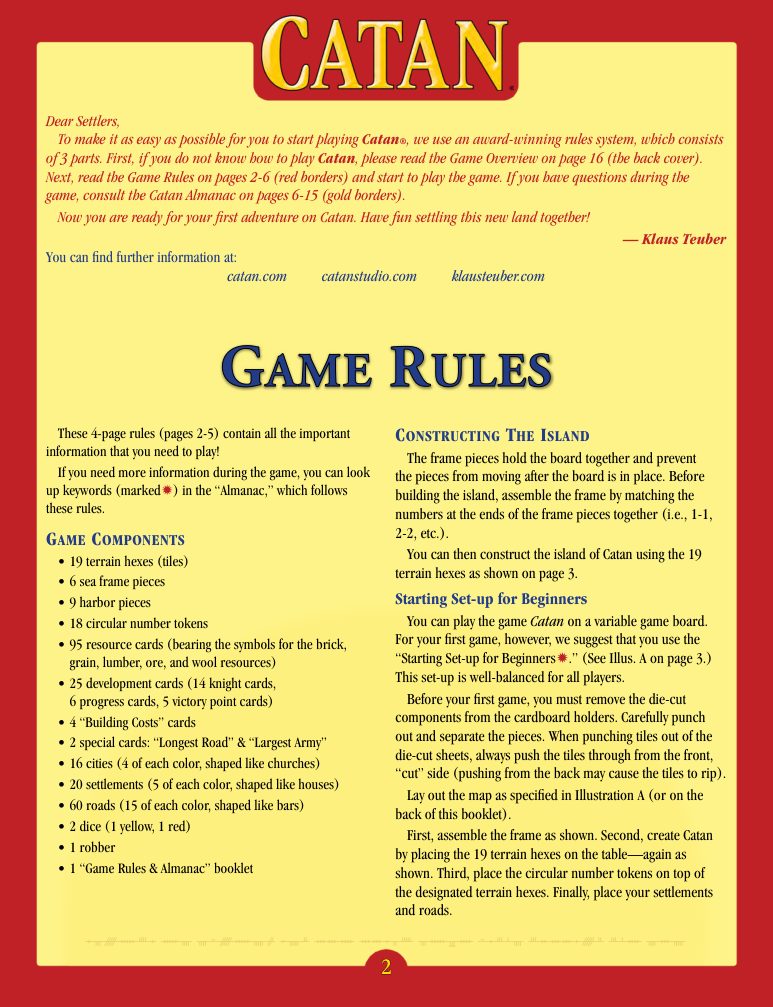

Catan PDF page 15


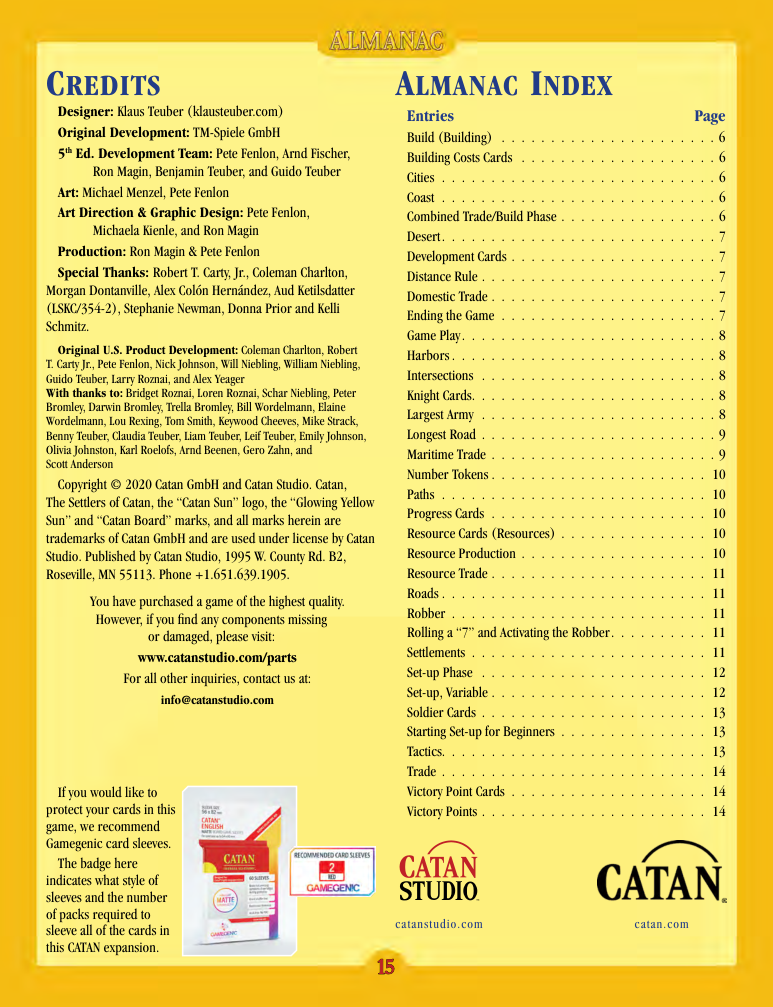

Catan PDF page 16


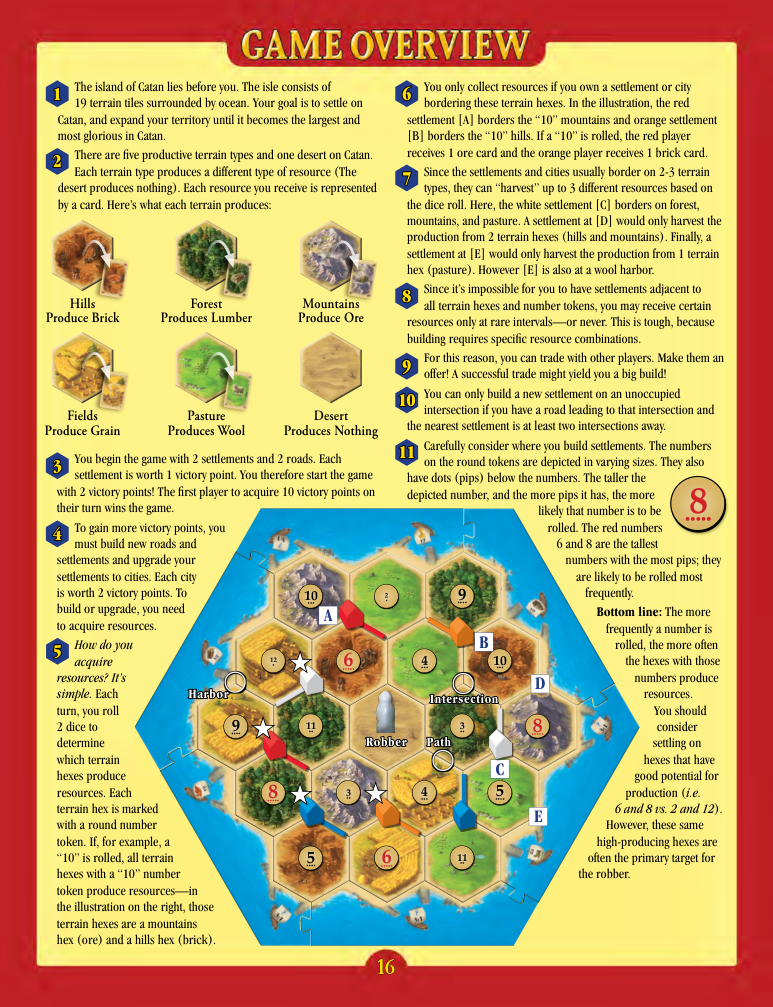

In [100]:
# Cell 27 — render the questionable Catan pages
from IPython.display import display
from PIL import Image
from io import BytesIO

CATAN_PATH = PDF_FILES["Catan"]

with pymupdf.open(CATAN_PATH) as pdf:

    for page_number in [2, 15, 16]:

        page = pdf[page_number - 1]

        pixmap = page.get_pixmap(
            matrix=pymupdf.Matrix(1.3, 1.3),
            alpha=False
        )

        image = Image.open(
            BytesIO(pixmap.tobytes("png"))
        )

        print(f"Catan PDF page {page_number}")
        display(image)

In [102]:
# Cell 28 — test retrieval before testing the agent
import sys
import os

# Move up one level to the project root directory
sys.path.append(os.path.abspath(os.path.join("..")))

from rag import retrieve_rules

TEST_QUESTIONS = {
    "catan": [
        "What happens when a player rolls a seven?",
        "How do settlements and roads get built?"
    ],

    "uno": [
        "When should a player call UNO?",
        "What happens when a player plays a Wild Draw Four card?"
    ],

    "monopoly": [
        "What happens when a player lands on an unowned property?",
        "What happens when a player cannot afford to pay rent?"
    ]
}


for game_id, questions in TEST_QUESTIONS.items():

    print("\n" + "=" * 85)
    print(f"GAME: {game_id.upper()}")
    print("=" * 85)

    for question in questions:

        print("\nQUESTION:", question)

        results = retrieve_rules(
            game_id=game_id,
            question=question,
            k=5
        )

        if not results:
            print("NO RESULTS FOUND")
            continue

        for rank, result in enumerate(results, start=1):

            print("\n" + "-" * 75)

            print("Rank:", rank)
            print("Page:", result["page_number"])
            print("Distance:", round(result["relevance_distance"], 4))
            print("Game:", result["game_name"])

            print("\nCONTENT:")
            print(result["content"][:550])


GAME: CATAN

QUESTION: What happens when a player rolls a seven?

---------------------------------------------------------------------------
Rank: 1
Page: 11
Distance: 0.5567
Game: Catan

CONTENT:
“7.” He must move the robber. The robber was in a fields hex.
 Xander places it on the “4” number token of a hills hex. If a
 “4” is rolled in the coming turns, the owners of settlements
 1111

---------------------------------------------------------------------------
Rank: 2
Page: 11
Distance: 0.5817
Game: Catan

CONTENT:
settlements and cities. You stacks. If you hold an odd number of cards, round down
build roads on paths Y. You (e.g., if you have 9 resource cards, you discard 4).
cannot build new settlements Example: Alex rolls a “7.” He has only 6 cards in his hand.
without also building roads. Larry has 8 cards and Will has 11. Larry must discard 4 cards
Roads provide victory points and Will 5 (rounding down).
only if you hold the Longest
 (2) Then you (the player who rolled the “7”)

In [ ]:
# 

In [ ]:
# 